# 7. Final comparison

Builds the comparison tables of Sections 3, 4 and 6 and the accuracy-versus-cost figures, from the
result files of notebooks 03 to 06. Nothing is trained or measured here, so it runs in seconds.

**Writes:** `results/tables/optimizer_comparison.md`, `custom_model_comparison.md` and
`final_comparison.md`; `results/figures/accuracy_vs_params.png` and `accuracy_vs_macs.png`.

## Setup

Folders, the random seed, the device, and small helpers for files and figures. Every notebook in
this folder starts with the same setup.

In [1]:
import json
import os
import platform
import random
import re
import subprocess
import sys
from pathlib import Path

import numpy as np
import torch
import torchvision

# Everything is read from and written to folders next to this notebook.
DATA_DIR = Path("data")                # the downloaded dataset and a decoded-pixel cache
RESULTS_DIR = Path("results")          # metrics, figures and tables
CHECKPOINT_DIR = Path("checkpoints")   # trained weights

SEED = 42            # fixes the split, the initial weights, augmentation and batch order
NUM_CLASSES = 10     # EuroSAT land-cover classes
INPUT_SHAPE = (3, 64, 64)

# cuBLAS needs this workspace setting for repeatable matrix products on a GPU.
CUBLAS_WORKSPACE = ":4096:8"


def seed_everything(seed, deterministic=True):
    """Seed Python, NumPy and PyTorch, so a run gives the same numbers every time.

    With ``deterministic=True``, cuDNN uses deterministic algorithms and stops
    auto-tuning, and PyTorch prefers deterministic implementations. This costs a
    little speed. Without it, two runs of the same experiment can differ by a few
    tenths of a percent, the same size as some differences between the models.
    A few GPU operations have no deterministic version; PyTorch then warns
    instead of stopping.
    """
    if deterministic:
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", CUBLAS_WORKSPACE)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # seeds the CPU and every GPU
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    torch.use_deterministic_algorithms(deterministic, warn_only=True)


def cpu_name():
    """The processor's model name, or an empty string if the operating system won't say."""
    name = ""
    try:
        if sys.platform == "win32":
            import winreg

            key = winreg.OpenKey(
                winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0"
            )
            name = str(winreg.QueryValueEx(key, "ProcessorNameString")[0])
        elif sys.platform.startswith("linux"):
            with open("/proc/cpuinfo", encoding="utf-8") as handle:
                for line in handle:
                    if line.lower().startswith("model name"):
                        name = line.split(":", 1)[1]
                        break
        elif sys.platform == "darwin":
            name = subprocess.run(
                ["sysctl", "-n", "machdep.cpu.brand_string"],
                capture_output=True, text=True, timeout=5, check=False,
            ).stdout
    except Exception:
        name = ""
    name = name or platform.processor() or ""
    name = re.sub(r"\((R|TM|C)\)", "", name, flags=re.IGNORECASE)  # trademark signs
    return " ".join(name.split())


def describe_device(device):
    """A readable name for a device, such as ``cuda:0 (Tesla T4)``.

    Every timing is recorded together with this name: a time means little
    without the hardware it was measured on.
    """
    device = torch.device(device)
    if device.type == "cuda":
        index = device.index if device.index is not None else torch.cuda.current_device()
        return f"cuda:{index} ({torch.cuda.get_device_name(index)})"
    name = cpu_name()
    return f"cpu ({name})" if name else "cpu"


#: Model name -> function building it; filled in by the model definitions below.
MODEL_BUILDERS = {}


def build_model(name, num_classes=NUM_CLASSES):
    """Seed PyTorch, then build ``name``: the same seed always gives the same initial weights.

    The three optimizer runs rely on this to start from identical weights, so
    that their comparison measures the optimizer and not the initialisation.
    """
    torch.manual_seed(SEED)
    return MODEL_BUILDERS[name](num_classes)


def count_parameters(model, trainable_only=True):
    """Number of parameters; frozen ones are left out when ``trainable_only``."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def model_size_kb(model):
    """Size of the saved weights (``state_dict``) in KB, where 1 KB = 1,024 bytes.

    Saving the weights, as a device would store them, rather than counting 4
    bytes per parameter, also counts buffers such as batch-norm statistics.
    """
    import io

    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1024


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python       {platform.python_version()} ({platform.system()})")
print(f"PyTorch      {torch.__version__}")
print(f"torchvision  {torchvision.__version__}")
print(f"NumPy        {np.__version__}")
print(f"Device       {describe_device(DEVICE)}")

Python       3.11.3 (Windows)
PyTorch      2.14.0+cu126
torchvision  0.29.0+cu126
NumPy        2.4.6
Device       cuda:0 (NVIDIA GeForce RTX 3050 Laptop GPU)


Figures are shown inline at a small size and saved at print quality. Each model and each optimizer
keeps one colour and one name in every figure and table.

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 100,            # inline figures: small, so the notebook stays light
    "savefig.dpi": 200,           # saved figures: print quality
    "savefig.bbox": "tight",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.8,
})

MODEL_LABELS = {
    "model_a": "Model A",
    "model_b": "Model B",
    "mobilenet_v2": "MobileNetV2",
    "squeezenet1_1": "SqueezeNet 1.1",
}
MODEL_COLORS = {
    "model_a": "#4C72B0",
    "model_b": "#DD8452",
    "mobilenet_v2": "#55A868",
    "squeezenet1_1": "#C44E52",
}
OPTIMIZER_LABELS = {"sgd": "SGD", "sgd_momentum": "SGD + momentum", "adam": "Adam"}
OPTIMIZER_COLORS = {"sgd": "#8172B3", "sgd_momentum": "#937860", "adam": "#DA8BC3"}


def save_figure(fig, path):
    """Save a figure as a PNG, creating its folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")

Results are saved as JSON and Markdown, so the tables can be rebuilt without retraining.

In [3]:
def write_json(path, payload):
    """Write ``payload`` as indented JSON, creating the folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2) + "\n", encoding="utf-8", newline="\n")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8", newline="\n")


def format_cell(value, spec=None):
    """One table cell: thousands separators for whole numbers, ``spec`` for decimals."""
    if value is None:
        return "-"
    if isinstance(value, bool):
        return str(value)
    if spec is not None and isinstance(value, (int, float)):
        return format(value, spec)
    if isinstance(value, int):
        return f"{value:,}"
    if isinstance(value, float):
        return f"{value:,.1f}" if abs(value) >= 1000 else f"{value:.4g}"
    return str(value).replace("|", "\\|")


def markdown_table(headers, rows, caption=None, formats=None):
    """A Markdown table. Number columns are right-aligned; ``formats`` fixes their decimals."""
    formats = formats or [None] * len(headers)

    def numeric(column):
        cells = [row[column] for row in rows if row[column] is not None]
        return bool(cells) and all(
            isinstance(cell, (int, float)) and not isinstance(cell, bool) for cell in cells
        )

    lines = [f"*{caption}*", ""] if caption else []
    lines.append("| " + " | ".join(headers) + " |")
    lines.append("|" + "|".join("---:" if numeric(c) else "---" for c in range(len(headers))) + "|")
    for row in rows:
        lines.append("| " + " | ".join(format_cell(v, s) for v, s in zip(row, formats)) + " |")
    return "\n".join(lines) + "\n"

## Building the comparison tables

The tables are built only from the saved result files, so they can be rebuilt without training
anything:

- `results/<run>/history.json`: each run's per-epoch record, written by notebooks 03 to 05;
- `results/<run>/test_metrics.json`: each run's test scores, written by the same notebooks;
- `results/benchmark.json`: each model's costs, written by notebook 06.

Mean epoch times come from the training runs, on the GPU; latency from notebook 06, on one CPU thread.

In [4]:
from IPython.display import Markdown, display
from matplotlib.ticker import EngFormatter

RUNS = {  # run name -> (model, optimizer)
    "model_b_sgd": ("model_b", "sgd"),
    "model_b_sgd_momentum": ("model_b", "sgd_momentum"),
    "model_b_adam": ("model_b", "adam"),
    "model_a_adam": ("model_a", "adam"),
    "mobilenet_v2_adam": ("mobilenet_v2", "adam"),
    "squeezenet1_1_adam": ("squeezenet1_1", "adam"),
}


def history_of(run):
    return read_json(RESULTS_DIR / run / "history.json")


def metrics_of(run):
    return read_json(RESULTS_DIR / run / "test_metrics.json")


def mean_epoch_time(history):
    return sum(row["epoch_time_s"] for row in history["epochs"]) / len(history["epochs"])


def optimizer_table():
    """Section 3: Model B with each optimizer, convergence and final performance."""
    rows = []
    for run in ("model_b_sgd", "model_b_sgd_momentum", "model_b_adam"):
        history, metrics = history_of(run), metrics_of(run)
        best = history["best_val_acc"]
        reached = next(row["epoch"] for row in history["epochs"] if row["val_acc"] >= 0.9 * best)
        rows.append([OPTIMIZER_LABELS[history["optimizer"]], history["hyperparameters"]["lr"],
                     history["best_epoch"], best * 100, metrics["accuracy"] * 100, reached,
                     mean_epoch_time(history)])
    return markdown_table(
        ["Optimizer", "Learning rate", "Best epoch", "Best validation accuracy (%)",
         "Test accuracy (%)", "Epoch to 90% of best", "Mean epoch time (s)"],
        rows, "Model B optimizer comparison.", [None, None, None, ".2f", ".2f", None, ".1f"])


def custom_model_table(benchmark):
    """Section 4: Model A against Model B."""
    rows = []
    for run in ("model_a_adam", "model_b_adam"):
        model, _ = RUNS[run]
        costs, metrics = benchmark[model], metrics_of(run)
        rows.append([MODEL_LABELS[model], costs["total_params"], costs["model_size_kb"],
                     costs["macs"], mean_epoch_time(history_of(run)), metrics["accuracy"] * 100,
                     metrics["macro_precision"] * 100, metrics["macro_recall"] * 100])
    return markdown_table(
        ["Model", "Total parameters", "Model size (KB)", "MACs", "Mean epoch time (s)",
         "Test accuracy (%)", "Macro precision (%)", "Macro recall (%)"],
        rows, "Model A and Model B comparison.",
        [None, None, ",.1f", None, ".1f", ".2f", ".2f", ".2f"])


def final_table(benchmark):
    """Section 6: Model B against the two pretrained models."""
    rows = []
    for run in ("model_b_adam", "mobilenet_v2_adam", "squeezenet1_1_adam"):
        model, _ = RUNS[run]
        costs, metrics = benchmark[model], metrics_of(run)
        rows.append([MODEL_LABELS[model], costs["trainable_params"], costs["total_params"],
                     costs["model_size_kb"], costs["model_size_kb"] / 1024, costs["macs"],
                     costs["latency_ms"], costs["peak_memory_mb"], metrics["accuracy"] * 100,
                     metrics["macro_precision"] * 100, metrics["macro_recall"] * 100])
    return markdown_table(
        ["Model", "Trainable parameters", "Total parameters", "Size (KB)", "Size (MB)", "MACs",
         "CPU latency (ms)", "Peak memory (MB)", "Test accuracy (%)", "Macro precision (%)",
         "Macro recall (%)"],
        rows, "Model B versus pretrained lightweight models.",
        [None, None, None, ",.1f", ".2f", None, ".2f", ".2f", ".2f", ".2f", ".2f"])

The trade-off in pictures. Parameters stand for memory: a device stores every weight, frozen or
not, so the total count is used. MACs stand for computation. The dashed line joins the models that
no other model beats on both cost and accuracy (the Pareto frontier); it is drawn only when more
than one model is on it.

In [5]:
def plot_tradeoff(benchmark, cost):
    """Test accuracy against ``total_params`` or ``macs`` for Model B and the pretrained models."""
    points = []
    for run in ("model_b_adam", "mobilenet_v2_adam", "squeezenet1_1_adam"):
        model, _ = RUNS[run]
        points.append((model, float(benchmark[model][cost]), metrics_of(run)["accuracy"] * 100))

    fig, ax = plt.subplots(figsize=(7, 5))
    for model, value, accuracy in points:
        ax.scatter(value, accuracy, color=MODEL_COLORS[model], s=70)
        ax.annotate(MODEL_LABELS[model], (value, accuracy), xytext=(6, 6), textcoords="offset points")

    frontier, best = [], float("-inf")
    for point in sorted(points, key=lambda p: p[1]):
        if point[2] > best:
            frontier.append(point)
            best = point[2]
    if len(frontier) > 1:
        ax.plot([p[1] for p in frontier], [p[2] for p in frontier], linestyle="--", color="0.35",
                label="Pareto frontier")
        ax.legend()

    label, name = {"total_params": ("Total parameters", "parameters"),
                   "macs": ("MACs per image", "MACs")}[cost]
    values = [p[1] for p in points]
    log_scale = max(values) > 10 * min(values)  # a log axis only when the costs span over a decade
    if log_scale:
        ax.set_xscale("log")
    ax.xaxis.set_major_formatter(EngFormatter(sep=""))  # 100k, 1M, 14M
    ax.margins(x=0.2, y=0.15)  # room for the labels beside the outermost points
    ax.set_xlabel(f"{label} (log scale)" if log_scale else label)
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title(f"Test accuracy versus {name}")
    fig.tight_layout()
    file_name = "accuracy_vs_macs.png" if cost == "macs" else "accuracy_vs_params.png"
    save_figure(fig, RESULTS_DIR / "figures" / file_name)
    plt.show()

## The result files

In [6]:
missing = [run for run in RUNS if not (RESULTS_DIR / run / "test_metrics.json").exists()]
if missing or not (RESULTS_DIR / "benchmark.json").exists():
    raise FileNotFoundError(f"run notebooks 03 to 06 first; missing: {missing or 'benchmark.json'}")
benchmark = read_json(RESULTS_DIR / "benchmark.json")

for run in RUNS:
    print(f"{run:<22} trained on {history_of(run)['device']}")
print(f"Latency measured on {benchmark['model_b']['device']}, one thread")

model_b_sgd            trained on cuda:0 (Tesla T4)
model_b_sgd_momentum   trained on cuda:0 (Tesla T4)
model_b_adam           trained on cuda:0 (Tesla T4)
model_a_adam           trained on cuda:0 (Tesla T4)
mobilenet_v2_adam      trained on cuda:0 (Tesla T4)
squeezenet1_1_adam     trained on cuda:0 (Tesla T4)
Latency measured on cpu (11th Gen Intel Core i5-11400H @ 2.70GHz), one thread


## Section 3: optimizers

In [7]:
tables = {}
tables["optimizer_comparison"] = optimizer_table()
display(Markdown(tables["optimizer_comparison"]))

*Model B optimizer comparison.*

| Optimizer | Learning rate | Best epoch | Best validation accuracy (%) | Test accuracy (%) | Epoch to 90% of best | Mean epoch time (s) |
|---|---:|---:|---:|---:|---:|---:|
| SGD | 0.01 | 27 | 89.83 | 90.25 | 5 | 11.4 |
| SGD + momentum | 0.01 | 29 | 96.25 | 96.32 | 4 | 11.4 |
| Adam | 0.001 | 29 | 96.25 | 96.17 | 3 | 11.3 |


## Section 4: Model A against Model B

In [8]:
tables["custom_model_comparison"] = custom_model_table(benchmark)
display(Markdown(tables["custom_model_comparison"]))

*Model A and Model B comparison.*

| Model | Total parameters | Model size (KB) | MACs | Mean epoch time (s) | Test accuracy (%) | Macro precision (%) | Macro recall (%) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Model A | 1,143,466 | 4,475.2 | 42,337,536 | 10.0 | 95.85 | 95.76 | 95.71 |
| Model B | 71,818 | 303.9 | 12,989,568 | 11.3 | 96.17 | 96.08 | 96.09 |


## Section 6: Model B against the pretrained models

In [9]:
tables["final_comparison"] = final_table(benchmark)
display(Markdown(tables["final_comparison"]))
for name, text in tables.items():
    write_text(RESULTS_DIR / "tables" / f"{name}.md", text)

*Model B versus pretrained lightweight models.*

| Model | Trainable parameters | Total parameters | Size (KB) | Size (MB) | MACs | CPU latency (ms) | Peak memory (MB) | Test accuracy (%) | Macro precision (%) | Macro recall (%) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Model B | 71,818 | 71,818 | 303.9 | 0.30 | 12,989,568 | 3.40 | 1.28 | 96.17 | 96.08 | 96.09 |
| MobileNetV2 | 1,218,890 | 2,236,682 | 8,971.1 | 8.76 | 24,461,312 | 6.22 | 9.41 | 95.38 | 95.23 | 95.16 |
| SqueezeNet 1.1 | 391,306 | 727,626 | 2,860.7 | 2.79 | 17,022,656 | 3.29 | 3.07 | 94.22 | 93.99 | 93.92 |


## Accuracy against cost

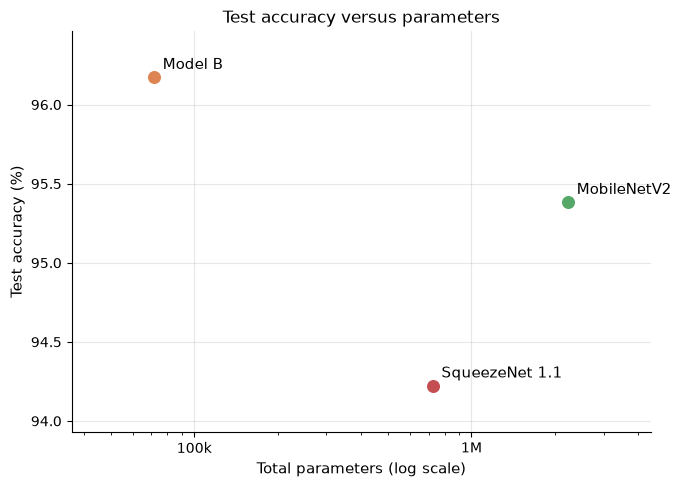

In [10]:
plot_tradeoff(benchmark, "total_params")

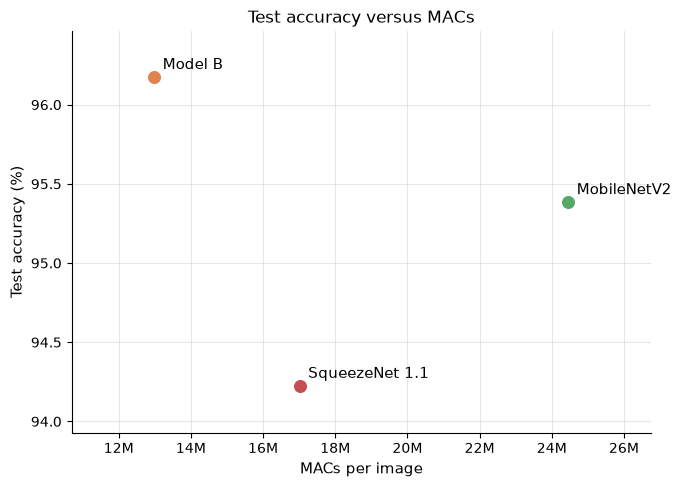

In [11]:
plot_tradeoff(benchmark, "macs")